In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score



In [2]:
df = pd.read_csv("Mall_Customers.csv")
print(df.shape)
print(df.head())
print(df.describe())
print(df.isnull().sum())

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
       CustomerID         Age  Annual Income (k$)  Spending Score (1-100)
count  200.000000  200.000000          200.000000              200.000000
mean   100.500000   38.850000           60.560000               50.200000
std     57.879185   13.969007           26.264721               25.823522
min      1.000000   18.000000           15.000000                1.000000
25%     50.750000   28.750000           41.500000               34.750000
50%    100.500000   36.000000           61.500000               50.000000
75%    150.250000   49.000000           78.0000

In [3]:
features = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
k_values = range(2,11)
inertias = []
silhouttes = []

for k in k_values:
    ks = KMeans(n_clusters=k, n_init=10, random_state=42)
    ks.fit(X_scaled)
    inertias.append(ks.inertia_)
    silhouttes.append(silhouette_score(X_scaled, ks.labels_))
    print(f"K:{k:.2f} Inerita:{ks.inertia_} silhoutte: {silhouttes[-1]:.3f}")

K:2.00 Inerita:269.6910121927639 silhoutte: 0.321
K:3.00 Inerita:157.7040081503595 silhoutte: 0.467
K:4.00 Inerita:108.92131661364357 silhoutte: 0.494
K:5.00 Inerita:65.56840815571681 silhoutte: 0.555
K:6.00 Inerita:55.057348270385994 silhoutte: 0.540
K:7.00 Inerita:44.86475569922558 silhoutte: 0.528
K:8.00 Inerita:37.228187677585886 silhoutte: 0.455
K:9.00 Inerita:32.39226763033117 silhoutte: 0.457
K:10.00 Inerita:29.98189778824369 silhoutte: 0.443


Text(0.5, 1.0, 'Silhouette Method')

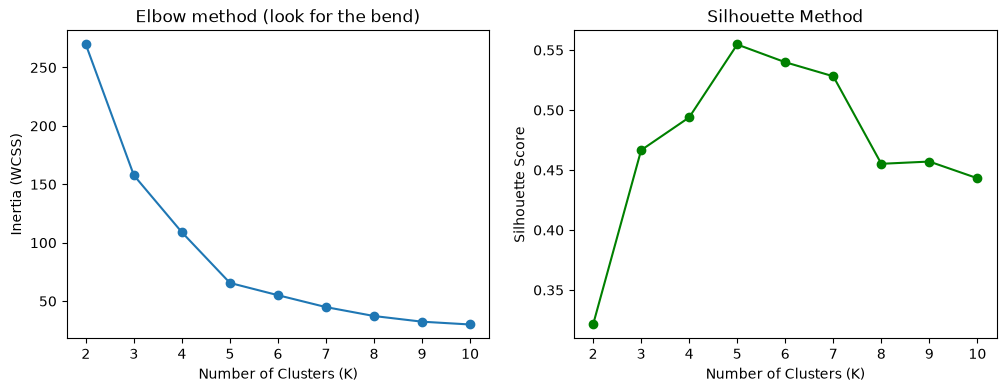

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(list(k_values), inertias, marker='o')
ax[0].set_xlabel("Number of Clusters (K)")
ax[0].set_ylabel("Inertia (WCSS)")
ax[0].set_title("Elbow method (look for the bend)")

ax[1].plot(list(k_values), silhouttes, marker='o', color='green')
ax[1].set_xlabel("Number of Clusters (K)")
ax[1].set_ylabel("Silhouette Score")
ax[1].set_title("Silhouette Method")

In [8]:
best_k = 5
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print(df["Cluster"].value_counts().sort_index())

Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


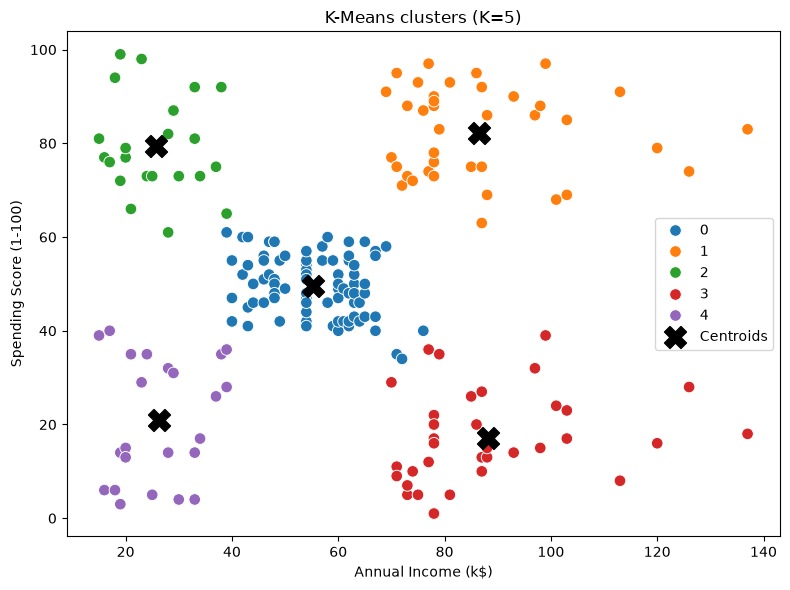

In [9]:
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df, x=features[0], y=features[1],
    hue="Cluster", palette="tab10", s=70
)

plt.scatter(
    centroids[:, 0], centroids[:, 1],
    marker="X", s=250, c="black", label="Centroids"
)

plt.title(f"K-Means clusters (K={best_k})")
plt.legend()
plt.tight_layout()
plt.show()